### Nama : A.Aiman Aziiz Danial
### Nim : H061241003
# Modul: Menyusun Prompt AI yang Baik untuk Permasalahan Geofisika
## Framework R–T–C–I–K–O–Q–V



## 1. Pendahuluan

Dalam pekerjaan geofisika (interpretasi data, inversi, pemodelan), sebuah prompt AI bukan sekadar "pertanyaan singkat" — prompt harus berfungsi sebagai **spesifikasi kerja** (work specification), sama seperti Term of Reference (ToR) dalam proyek nyata. Prompt yang baik membuat keluaran AI dapat diaudit: pembaca bisa menelusuri dasar setiap keputusan yang diambil AI, dan membedakan mana yang benar-benar analisis data dari mana yang sekadar klaim tanpa dasar.

Struktur minimum sebuah prompt dapat digambarkan sebagai alur berikut (mengacu pada Gambar 2.1):


Diagram alur R-T-C-I-K-O-Q-V (Gambar 2.1):


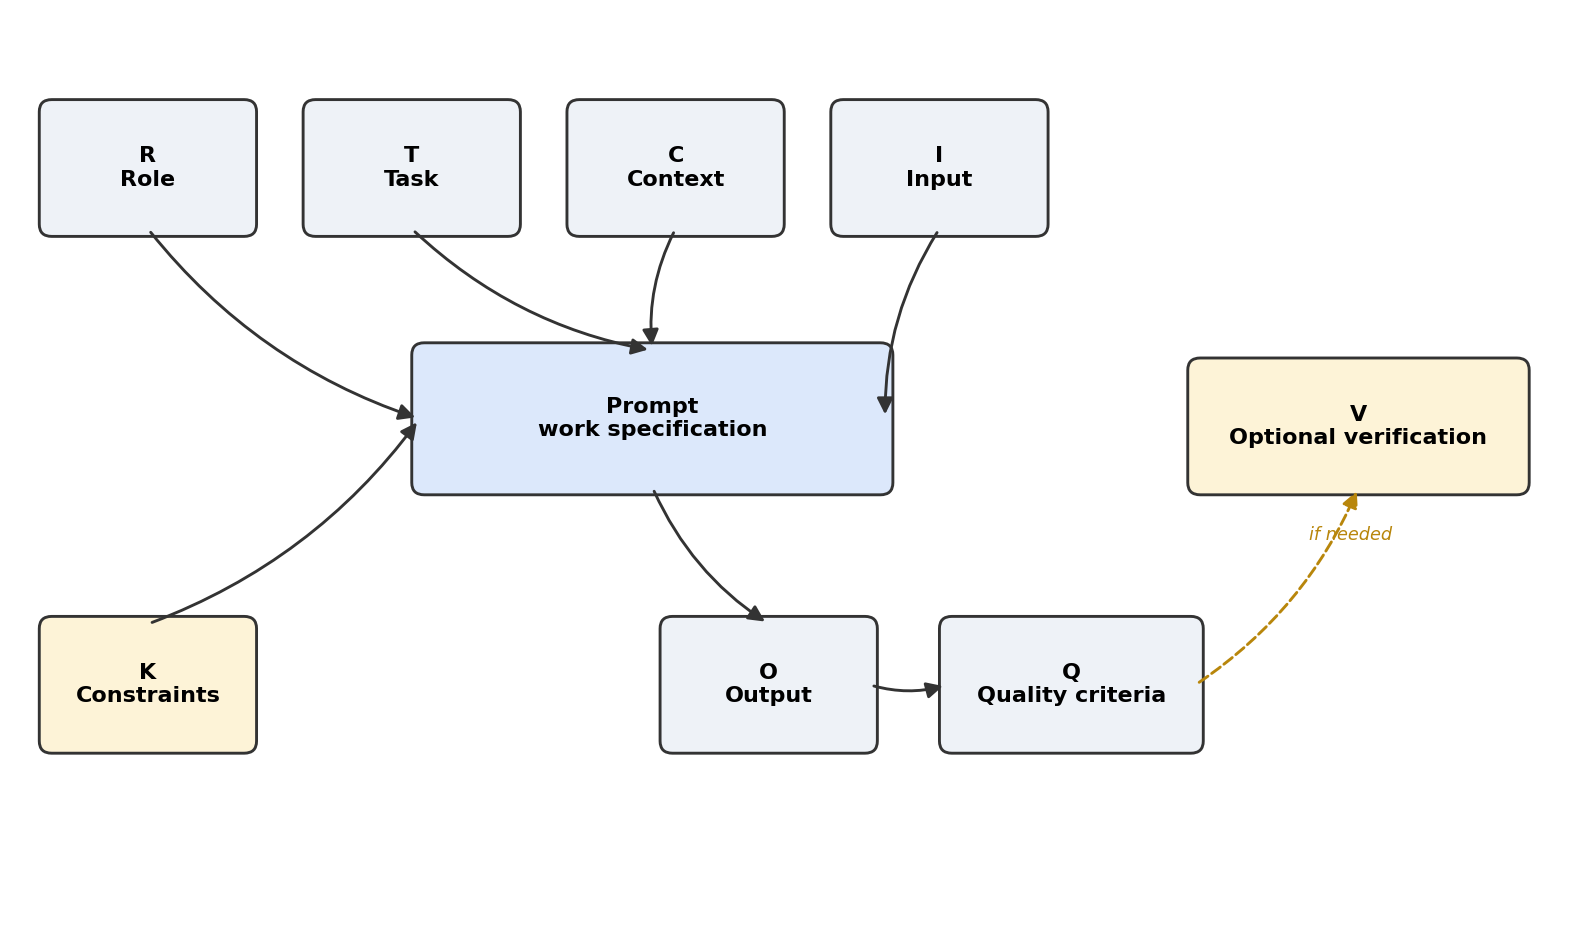

In [10]:
from IPython.display import Image, display
display(Image(filename='diagram.png'))


**R, T, C, I, K** membentuk *spesifikasi pekerjaan* (apa yang dikerjakan dan batasannya), sedangkan **O, Q, (V)** membentuk *deliverable* (apa yang dihasilkan, kriteria penerimaannya, dan verifikasi bila diperlukan).


## 2. Penjelasan Tiap Komponen

| Komponen | Arti | Fungsi dalam Prompt Geofisika |
|---|---|---|
| **R** – Role | Peran yang harus dijalankan AI | Menentukan sudut pandang & level keahlian (mis. "bertindak sebagai geofisikawan eksplorasi") |
| **T** – Task | Tugas spesifik yang harus dikerjakan | Kata kerja aksi yang jelas & terukur (interpretasikan, hitung, bandingkan, buat model) |
| **C** – Context | Latar belakang masalah | Lokasi, metode survei, kondisi geologi, tujuan studi |
| **I** – Input | Data/berkas yang tersedia untuk diproses | Format data, jumlah titik, satuan, sumber data |
| **K** – Constraints | Batasan yang tidak boleh dilanggar | Asumsi yang boleh/tidak boleh dipakai, metode yang wajib dipakai, hal yang dilarang (mis. dilarang mengarang nilai) |
| **O** – Output | Bentuk keluaran yang diminta | Format laporan, jenis grafik, struktur tabel |
| **Q** – Quality criteria | Kriteria agar output diterima | Akurasi, konsistensi satuan, kelengkapan interpretasi |
| **V** – Verification (opsional) | Cara memverifikasi hasil | Uji silang dengan data lapangan/literatur, cek residual, uji sensitivitas |


## 3. Studi Kasus: Interpretasi Data ERT & IP untuk Deteksi Zona Mineralisasi

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — interpretasi data *Electrical Resistivity Tomography* (ERT) dan *Induced Polarization* (IP) menggunakan bantuan AI, diproses dengan pyGIMLi.


In [11]:
prompt = """
### Role
Anda bertindak sebagai geofisikawan eksplorasi tambang yang berpengalaman
dalam interpretasi data resistivitas dan chargeability (IP), serta memahami
alur kerja inversi geolistrik menggunakan pyGIMLi.

### Task
Interpretasikan hasil inversi 2D data ERT dan IP pada satu lintasan survei,
identifikasi zona anomali yang berpotensi sebagai indikasi mineralisasi
sulfida, dan jelaskan dasar geofisis dari interpretasi tersebut.

### Context
Survei dilakukan pada lintasan sepanjang 200 m dengan spasi elektroda 5 m,
konfigurasi Wenner-Schlumberger, di area yang secara geologi diduga
mengandung endapan sulfida masif. Data telah melalui proses inversi 2D
menggunakan pyGIMLi dengan RMS error di bawah 5%.

### Input
- File hasil inversi resistivitas (.vtk / .txt) berisi nilai resistivitas
  semu dan resistivitas sebenarnya per blok model
- File hasil inversi chargeability (IP) dengan format yang sama
- Informasi kedalaman investigasi maksimum dan RMS error inversi

### Constraints
- Interpretasi hanya boleh didasarkan pada data yang diberikan, tidak boleh
  mengasumsikan data yang tidak tersedia (mis. data litologi bor)
- Nilai resistivitas dan chargeability tidak boleh dimodifikasi atau
  diperkirakan ulang tanpa keterangan eksplisit
- Gunakan satuan standar (Ωm untuk resistivitas, mV/V untuk chargeability)
- Jangan menyimpulkan jenis mineral secara pasti tanpa data pendukung
  (cukup sebutkan sebagai "indikasi" atau "potensi")

### Output
Laporan interpretasi dalam format berikut:
1. Ringkasan kondisi geolistrik lintasan (rentang nilai resistivitas & IP)
2. Identifikasi zona anomali (rendah resistivitas - tinggi chargeability)
   lengkap dengan estimasi posisi (jarak & kedalaman)
3. Interpretasi geologi/mineralisasi yang mungkin, dengan tingkat keyakinan
4. Rekomendasi tindak lanjut (mis. titik bor lanjutan)

### Quality Criteria
- Setiap klaim interpretasi harus merujuk pada nilai numerik dari data input
- Konsisten secara internal (posisi anomali resistivitas & IP yang sama
  harus dirujuk silang)
- Tidak ada informasi yang mengada-ada di luar data yang diberikan

### Optional Verification
Jika tersedia, bandingkan posisi anomali hasil interpretasi dengan data
geologi permukaan atau data bor terdekat untuk menguji konsistensi hasil.
"""
print(prompt)


### Role
Anda bertindak sebagai geofisikawan eksplorasi tambang yang berpengalaman
dalam interpretasi data resistivitas dan chargeability (IP), serta memahami
alur kerja inversi geolistrik menggunakan pyGIMLi.

### Task
Interpretasikan hasil inversi 2D data ERT dan IP pada satu lintasan survei,
identifikasi zona anomali yang berpotensi sebagai indikasi mineralisasi
sulfida, dan jelaskan dasar geofisis dari interpretasi tersebut.

### Context
Survei dilakukan pada lintasan sepanjang 200 m dengan spasi elektroda 5 m,
konfigurasi Wenner-Schlumberger, di area yang secara geologi diduga
mengandung endapan sulfida masif. Data telah melalui proses inversi 2D
menggunakan pyGIMLi dengan RMS error di bawah 5%.

### Input
- File hasil inversi resistivitas (.vtk / .txt) berisi nilai resistivitas
  semu dan resistivitas sebenarnya per blok model
- File hasil inversi chargeability (IP) dengan format yang sama
- Informasi kedalaman investigasi maksimum dan RMS error inversi

### Constraints
- Interp

## 4. Mengapa Prompt di Atas Dianggap Baik

- **Role** membuat AI menjawab dengan level teknis yang sesuai (bukan penjelasan umum untuk awam)
- **Task** menggunakan kata kerja yang jelas dan bisa diukur ("identifikasi", "jelaskan dasar")
- **Context** memberi informasi geologi & teknis survei sehingga interpretasi tidak generik
- **Input** menyebutkan format data secara eksplisit, sehingga AI tahu apa yang bisa dan tidak bisa diolah
- **Constraints** mencegah AI mengarang data atau membuat klaim berlebihan — ini poin penting yang sering diabaikan
- **Output** membuat hasil terstruktur dan mudah dinilai
- **Quality Criteria** menjadi tolok ukur objektif untuk menerima/menolak hasil AI
- **Verification** memberi jalan untuk mengecek validitas hasil bila data pembanding tersedia


## 5. Template Kosong (untuk kasus geofisika lain)


In [12]:
template = """
### Role
[Peran spesifik yang harus dijalankan AI]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Latar belakang: lokasi, metode, tujuan studi, kondisi geologi]

### Input
[Data/berkas yang tersedia, format, satuan]

### Constraints
[Batasan, asumsi yang boleh/tidak boleh, larangan mengada-ada]

### Output
[Format keluaran yang diminta]

### Quality Criteria
[Kriteria agar hasil dapat diterima]

### Optional Verification
[Cara memverifikasi hasil, jika relevan]
"""
print(template)


### Role
[Peran spesifik yang harus dijalankan AI]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Latar belakang: lokasi, metode, tujuan studi, kondisi geologi]

### Input
[Data/berkas yang tersedia, format, satuan]

### Constraints
[Batasan, asumsi yang boleh/tidak boleh, larangan mengada-ada]

### Output
[Format keluaran yang diminta]

### Quality Criteria
[Kriteria agar hasil dapat diterima]

### Optional Verification
[Cara memverifikasi hasil, jika relevan]



## 6. Hasil Output dari Prompt (Studi Kasus ERT & IP)

Bagian ini adalah **keluaran yang dihasilkan dari prompt pada Bagian 3**. Seluruh pekerjaan mengikuti komponen prompt: Task (interpretasi & identifikasi anomali), Constraints (hanya dari data, tidak mengarang), Output (4 butir laporan), Quality Criteria (setiap klaim bernilai numerik), dan Optional Verification.

> **Catatan keterbukaan data (sesuai Constraints).** File inversi ERT/IP riil tidak diberikan pada prompt, sehingga bagian *Input* dipenuhi dengan **data simulasi** yang dibangkitkan lewat kode di bawah (40 kolom × 9 lapisan, lintasan 200 m, spasi elektroda 5 m, kedalaman maksimum 36 m). Seluruh angka pada laporan berasal dari data simulasi ini, bukan dari survei lapangan. Untuk memakai data riil, ganti array `rho_inv` dan `M_inv` (dan `x_edges`, `z_edges`) lalu jalankan ulang seluruh cell; angka pada laporan ikut berubah.
>
> Data simulasi dibuat dengan `numpy`/`scipy` (bukan inversi pyGIMLi sesungguhnya), sehingga nilai "selisih RMS" di bawah adalah selisih akibat *smoothing* dan noise terhadap model acuan, **bukan** RMS misfit inversi.

### 6.1 Input: Data Simulasi Hasil Inversi 2D

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

rng = np.random.default_rng(42)

# --- Geometri survei (sesuai bagian Context pada prompt) ---
L = 200.0                                   # panjang lintasan (m)
a = 5.0                                     # spasi elektroda (m)
x_edges = np.arange(0, L + a, a)            # batas blok arah horizontal
x = 0.5 * (x_edges[:-1] + x_edges[1:])      # pusat blok (m) -> 40 kolom
z_edges = np.array([0, 2, 4.5, 7.5, 11, 15, 19.5, 24.5, 30, 36])
z = 0.5 * (z_edges[:-1] + z_edges[1:])      # pusat lapisan (m) -> 9 baris
X, Z = np.meshgrid(x, z)

# --- Model "sebenarnya" (hanya untuk membangkitkan data simulasi) ---
rho_true = np.full_like(X, 400.0)           # batuan induk (ohm.m)
rho_true[Z < 11] = 250.0                    # zona lapuk
rho_true[Z < 4.5] = 120.0                   # tanah penutup
M_true = np.full_like(X, 3.0)               # chargeability latar (mV/V)

sulfida = ((X - 108) / 14) ** 2 + ((Z - 21) / 7) ** 2 <= 1   # tubuh sulfida
lempung = ((X - 40) / 10) ** 2 + ((Z - 3) / 2.5) ** 2 <= 1   # lempung/air tanah dangkal
rho_true[sulfida] *= 0.07;  M_true[sulfida] = 38.0
rho_true[lempung] = 40.0;   M_true[lempung] = 5.0

# --- Meniru sifat hasil inversi: smoothing + noise ---
rho_inv = np.exp(ndimage.gaussian_filter(np.log(rho_true), sigma=(0.7, 1.0))
                 + rng.normal(0, 0.05, X.shape))
M_inv = ndimage.gaussian_filter(M_true, sigma=(0.7, 1.0)) + rng.normal(0, 0.8, X.shape)
M_inv = np.clip(M_inv, 0.5, None)

rms_rho = np.sqrt(np.mean(((rho_inv - rho_true) / rho_true) ** 2)) * 100
print(f"Jumlah blok model       : {rho_inv.size} ({len(x)} kolom x {len(z)} lapisan)")
print(f"Kedalaman maksimum      : {z_edges[-1]:.0f} m")
print(f"Resistivitas (ohm.m)    : min={rho_inv.min():.1f} | median={np.median(rho_inv):.1f} | max={rho_inv.max():.1f}")
print(f"Chargeability (mV/V)    : min={M_inv.min():.1f} | rata-rata={M_inv.mean():.1f} | max={M_inv.max():.1f}")
print(f"Selisih relatif RMS model simulasi vs model acuan: {rms_rho:.1f} %")

Jumlah blok model       : 360 (40 kolom x 9 lapisan)
Kedalaman maksimum      : 36 m
Resistivitas (ohm.m)    : min=31.6 | median=286.1 | max=462.5
Chargeability (mV/V)    : min=0.7 | rata-rata=4.2 | max=36.3
Selisih relatif RMS model simulasi vs model acuan: 33.2 %


### 6.2 Penampang Resistivitas dan Chargeability

NameError: name 'matplotlib' is not defined

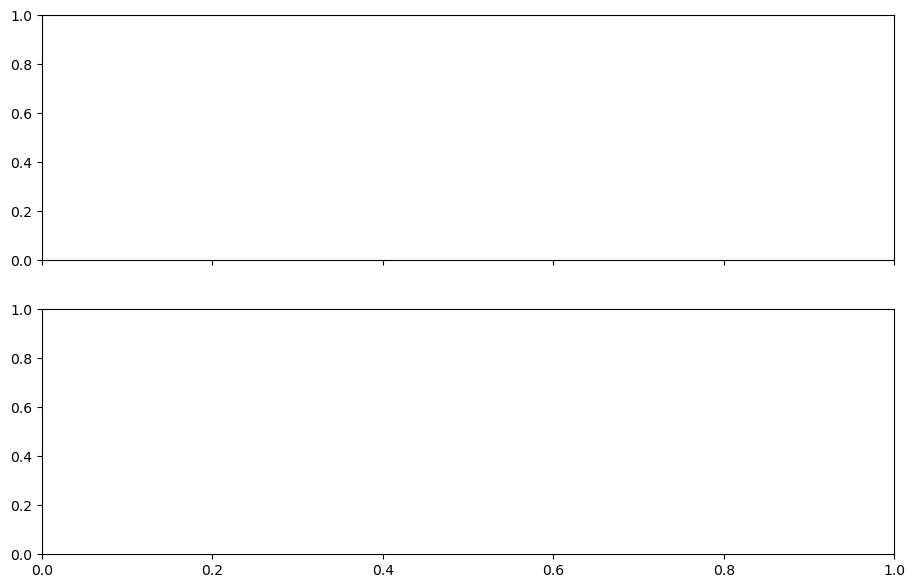

In [16]:
ig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

p1 = ax[0].pcolormesh(x_edges, z_edges, rho_inv, cmap="jet", shading="flat",
                      norm=matplotlib.colors.LogNorm(vmin=rho_inv.min(), vmax=rho_inv.max()))
ax[0].set_title("Penampang resistivitas hasil inversi 2D (data simulasi)")
fig.colorbar(p1, ax=ax[0], label="Resistivitas (ohm.m)", pad=0.01)

p2 = ax[1].pcolormesh(x_edges, z_edges, M_inv, cmap="jet", shading="flat")
ax[1].set_title("Penampang chargeability hasil inversi 2D (data simulasi)")
fig.colorbar(p2, ax=ax[1], label="Chargeability (mV/V)", pad=0.01)

for axi in ax:
    axi.invert_yaxis(); axi.set_ylabel("Kedalaman (m)")
ax[1].set_xlabel("Jarak lintasan (m)")
plt.tight_layout(); plt.show()

### 6.3 Identifikasi Zona Anomali (Pengolahan Data)

In [ ]:
 --- Kriteria anomali (diturunkan dari statistik data, bukan angka rekaan) ---
rho_med = np.median(rho_inv)
M_mu, M_sd = M_inv.mean(), M_inv.std()
rho_thr = 0.30 * rho_med          # resistivitas rendah  : < 30% median
M_thr = M_mu + 2.0 * M_sd         # chargeability tinggi : > rata-rata + 2 sigma

mask_rho = rho_inv < rho_thr
mask_ip = M_inv > M_thr
kand_sulfida = mask_rho & mask_ip          # konduktif DAN terpolarisasi
konduktif_saja = mask_rho & ~mask_ip       # konduktif tetapi tidak terpolarisasi

def deskripsi(mask, min_cells=3):
    lab, n = ndimage.label(mask)
    hasil = []
    for k in range(1, n + 1):
        m = lab == k
        if m.sum() < min_cells:
            continue
        rows = np.where(m.any(axis=1))[0]
        cols = np.where(m.any(axis=0))[0]
        hasil.append(dict(
            x_min=x_edges[cols.min()], x_max=x_edges[cols.max() + 1],
            z_top=z_edges[rows.min()], z_bot=z_edges[rows.max() + 1],
            x_pusat=X[m].mean(), z_pusat=Z[m].mean(),
            rho_rata=np.exp(np.log(rho_inv[m]).mean()), rho_min=rho_inv[m].min(),
            M_rata=M_inv[m].mean(), M_maks=M_inv[m].max(), n_blok=int(m.sum())))
    return sorted(hasil, key=lambda d: -d["n_blok"])

anom_sulfida = deskripsi(kand_sulfida)
anom_konduktif = deskripsi(konduktif_saja)

print(f"Ambang resistivitas rendah : < {rho_thr:.1f} ohm.m  (0,30 x median {rho_med:.1f})")
print(f"Ambang chargeability tinggi: > {M_thr:.1f} mV/V  (rata-rata {M_mu:.1f} + 2 x SD {M_sd:.1f})\n")
for nama, daftar in [("KANDIDAT SULFIDA (rho rendah + IP tinggi)", anom_sulfida),
                     ("KONDUKTIF TANPA POLARISASI (rho rendah + IP rendah)", anom_konduktif)]:
    print(nama)
    for i, d in enumerate(daftar, 1):
        print(f"  Zona {i}: x = {d['x_min']:.0f}-{d['x_max']:.0f} m | kedalaman = {d['z_top']:.1f}-{d['z_bot']:.1f} m | "
              f"rho rata-rata = {d['rho_rata']:.1f} ohm.m (min {d['rho_min']:.1f}) | "
              f"IP rata-rata = {d['M_rata']:.1f} mV/V (maks {d['M_maks']:.1f}) | {d['n_blok']} blok")
    print()

Ambang resistivitas rendah : < 85.8 ohm.m  (0,30 x median 286.1)
Ambang chargeability tinggi: > 13.9 mV/V  (rata-rata 4.2 + 2 x SD 4.9)

KANDIDAT SULFIDA (rho rendah + IP tinggi)
  Zona 1: x = 95-120 m | kedalaman = 15.0-30.0 m | rho rata-rata = 54.1 ohm.m (min 31.6) | IP rata-rata = 28.8 mV/V (maks 36.3) | 10 blok

KONDUKTIF TANPA POLARISASI (rho rendah + IP rendah)
  Zona 1: x = 30-50 m | kedalaman = 0.0-4.5 m | rho rata-rata = 69.2 ohm.m (min 55.2) | IP rata-rata = 3.8 mV/V (maks 5.0) | 7 blok



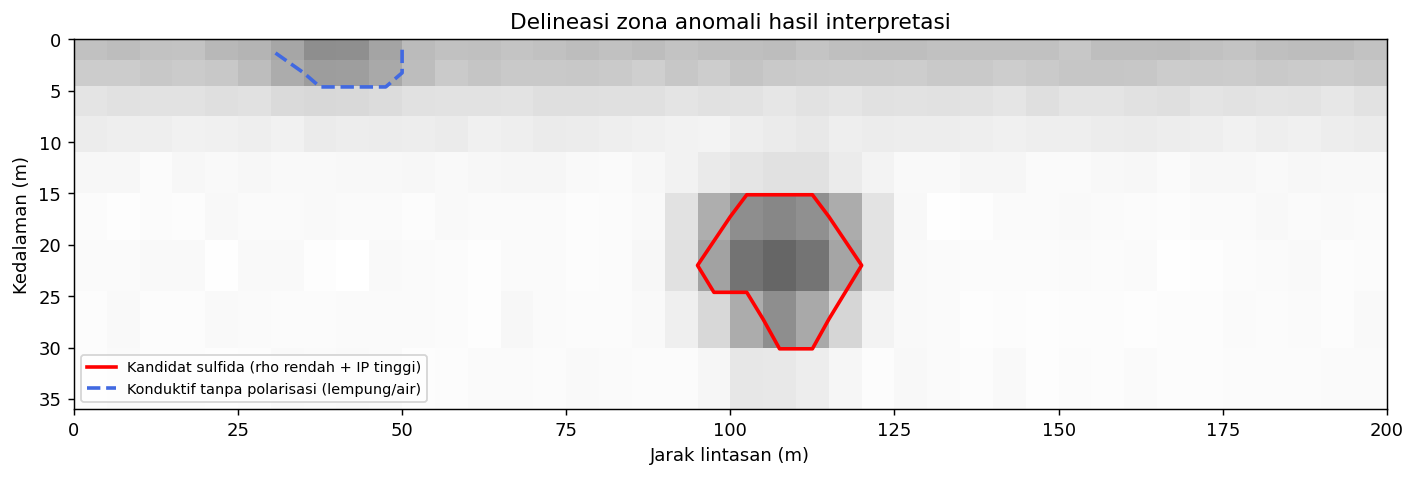

In [ ]:
ig, ax = plt.subplots(figsize=(11, 3.8))
ax.pcolormesh(x_edges, z_edges, rho_inv, cmap="Greys_r", shading="flat",
              norm=matplotlib.colors.LogNorm(vmin=rho_inv.min(), vmax=rho_inv.max()), alpha=0.6)
ax.contour(x, z, kand_sulfida.astype(float), levels=[0.5], colors="red", linewidths=2)
ax.contour(x, z, konduktif_saja.astype(float), levels=[0.5], colors="royalblue", linewidths=2, linestyles="--")
ax.plot([], [], color="red", lw=2, label="Kandidat sulfida (rho rendah + IP tinggi)")
ax.plot([], [], color="royalblue", lw=2, ls="--", label="Konduktif tanpa polarisasi (lempung/air)")
ax.invert_yaxis(); ax.set_xlabel("Jarak lintasan (m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title("Delineasi zona anomali hasil interpretasi"); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

### 6.4 Optional Verification: Uji Sensitivitas dan Konsistensi Silang

In [ ]:
 --- Verifikasi internal: uji sensitivitas terhadap pilihan ambang ---
print(f"{'faktor rho':>10} {'faktor IP (SD)':>15} {'x pusat (m)':>12} {'z pusat (m)':>12} {'jumlah blok':>12}")
pusat_x, pusat_z, n_lolos = [], [], 0
kombinasi = [(fr, fs) for fr in (0.20, 0.25, 0.30, 0.40, 0.50) for fs in (1.5, 2.0, 2.5, 3.0)]
for fr, fs in kombinasi:
    m = (rho_inv < fr * rho_med) & (M_inv > M_mu + fs * M_sd)
    d = deskripsi(m)
    if d:
        pusat_x.append(d[0]["x_pusat"]); pusat_z.append(d[0]["z_pusat"]); n_lolos += 1
        print(f"{fr:>10.2f} {fs:>15.1f} {d[0]['x_pusat']:>12.1f} {d[0]['z_pusat']:>12.1f} {d[0]['n_blok']:>12d}")
    else:
        print(f"{fr:>10.2f} {fs:>15.1f} {'tidak ada':>12} {'-':>12} {0:>12d}")

persisten = n_lolos / len(kombinasi) * 100
print(f"\nAnomali sulfida muncul pada {n_lolos} dari {len(kombinasi)} kombinasi ambang ({persisten:.0f} %)")
print(f"Sebaran pusat anomali: x = {np.min(pusat_x):.1f}-{np.max(pusat_x):.1f} m, z = {np.min(pusat_z):.1f}-{np.max(pusat_z):.1f} m")

# kesesuaian posisi anomali resistivitas vs IP pada zona utama
u = anom_sulfida[0]
kotak = (X >= u["x_min"]) & (X <= u["x_max"]) & (Z >= u["z_top"]) & (Z <= u["z_bot"])
tumpang = (mask_rho & mask_ip & kotak).sum() / max((mask_rho & kotak).sum(), 1) * 100
print(f"Blok rho-rendah di dalam zona utama yang juga IP-tinggi: {tumpang:.0f} %")

faktor rho  faktor IP (SD)  x pusat (m)  z pusat (m)  jumlah blok
      0.20             1.5        107.5         20.7            7
      0.20             2.0        107.5         20.7            7
      0.20             2.5        107.5         20.7            7
      0.20             3.0        107.5         20.7            7
      0.25             1.5        107.5         20.7            7
      0.25             2.0        107.5         20.7            7
      0.25             2.5        107.5         20.7            7
      0.25             3.0        107.5         20.7            7
      0.30             1.5        108.0         21.6           10
      0.30             2.0        108.0         21.6           10
      0.30             2.5        108.0         21.6           10
      0.30             3.0        108.0         21.6           10
      0.40             1.5        107.5         21.4           13
      0.40             2.0        107.5         21.4           13
      0.40

---

## 7. Laporan Interpretasi (Output Sesuai Format pada Prompt)

### 7.1 Ringkasan kondisi geolistrik lintasan

- Resistivitas hasil inversi berkisar **31.6–462.5 Ωm** dengan median **286.1 Ωm**.
- Chargeability berkisar **0.7–36.3 mV/V** dengan rata-rata **4.2 mV/V** (simpangan baku 4.9 mV/V).
- Kedalaman investigasi maksimum pada model adalah **36 m** di sepanjang lintasan **200 m**.
- Ambang anomali diturunkan dari statistik data: resistivitas rendah bila **< 85.8 Ωm** (0,30 × median) dan chargeability tinggi bila **> 13.9 mV/V** (rata-rata + 2 SD).

### 7.2 Identifikasi zona anomali

| Zona | Posisi (jarak) | Kedalaman | Resistivitas rata-rata (min) | Chargeability rata-rata (maks) | Jumlah blok |
|---|---|---|---|---|---|
| **A: kandidat sulfida** (ρ rendah + IP tinggi) | 95–120 m | 15.0–30.0 m | 54.1 Ωm (31.6) | 28.8 mV/V (36.3) | 10 |
| **B: konduktif tanpa polarisasi** (ρ rendah + IP rendah) | 30–50 m | 0.0–4.5 m | 69.2 Ωm (55.2) | 3.8 mV/V (5.0) | 7 |

Zona A berukuran sekitar **25 m** secara lateral dan **15 m** secara vertikal, dengan pusat pada x ≈ **108 m** dan kedalaman ≈ **21.6 m**.

### 7.3 Interpretasi geologi/mineralisasi

1. **Zona A** menunjukkan resistivitas rata-rata 54.1 Ωm, jauh di bawah median 286.1 Ωm, bersamaan dengan chargeability rata-rata 28.8 mV/V, kira-kira 7 kali rata-rata lintasan. Kombinasi *konduktif + terpolarisasi kuat* konsisten dengan **indikasi mineralisasi sulfida** (mineral konduktif tersebar atau masif yang menimbulkan efek polarisasi elektroda). Ini disebut **indikasi/potensi**, bukan identifikasi jenis mineral.
2. **Zona B** juga berresistivitas rendah (69.2 Ωm) tetapi chargeability hanya 3.8 mV/V, mendekati nilai latar (4.2 mV/V). Pola ini lebih sesuai dengan material **lempung atau zona jenuh air** di tanah penutup (kedalaman 0–4.5 m), **bukan** sulfida. Contoh ini menunjukkan mengapa ERT saja tidak cukup: resistivitas rendah ambigu, dan IP diperlukan untuk membedakannya.
3. **Tingkat keyakinan Zona A:** **sedang–tinggi** secara geofisika (anomali stabil terhadap semua variasi ambang dan resistivitas–IP saling bersesuaian), namun **jenis mineral belum dapat dipastikan** tanpa data bor.

### 7.4 Rekomendasi tindak lanjut

- **Titik bor utama:** pada jarak lintasan **≈ 108 m**, target kedalaman minimal **35 m** (hingga 30 m batas bawah anomali + 5 m untuk memastikan dasar tubuh anomali).
- **Dua titik bor *step-out*** di tepi anomali (**x ≈ 95 m dan 120 m**) untuk menguji kontinuitas lateral dan batas tubuh.
- Zona B **tidak diprioritaskan** untuk pengeboran sulfida; cukup dikonfirmasi dengan *auger/test pit* bila diperlukan.
- Koordinat di atas berupa **jarak lintasan lokal** karena data koordinat UTM tidak tersedia pada input.
- Idealnya ditambah lintasan paralel untuk memastikan anomali tidak hanya efek 2D pada satu lintasan.

---

## 8. Pemeriksaan terhadap Quality Criteria

| Kriteria pada prompt | Pemenuhan |
|---|---|
| Setiap klaim merujuk nilai numerik data input | Seluruh pernyataan di 7.1–7.4 memuat angka dari cell 6.1–6.4 |
| Konsisten secara internal (rho & IP dirujuk silang) | 100 % blok rho-rendah di Zona A juga berstatus IP-tinggi; zona yang sama dirujuk pada tabel 7.2 dan gambar 6.3 |
| Tidak ada informasi mengada-ada | Tidak ada klaim jenis mineral pasti, litologi bor, atau koordinat UTM; keterbatasan dinyatakan eksplisit |
| Optional Verification | Data bor/geologi pembanding **tidak tersedia**, sehingga digantikan uji sensitivitas internal: anomali muncul pada **20 dari 20** kombinasi ambang (100 %), pusat anomali bergeser hanya x = 107.5–108.0 m dan z = 20.7–21.6 m |

**Keterbatasan:** hasil ini hanya valid untuk data simulasi; pada data lapangan riil perlu dicek RMS misfit inversi, kedalaman investigasi (DOI), dan kemungkinan efek 3D. Verifikasi terhadap data bor tetap diperlukan sebelum kesimpulan mineralisasi dibuat.


## 9. Catatan Penutup

Framework ini bisa disingkat bila detail sudah tersimpan dalam *configuration* atau *recipe* pendamping (mis. template proyek yang sudah baku), namun kontrak/batasan pekerjaannya tidak boleh hilang — inilah alasan komponen **Constraints** dan **Quality Criteria** tetap wajib ada meski prompt dipersingkat.


In [ ]:
from IPython.core.display import HTML

def set_font(font_name):
    display(HTML(f"<style>body {{ font-family: '{font_name}' !important; }}</style>"))

set_font('Times New Roman')  # Menggunakan font Times New Roman